In [1]:
import sys
sys.path.insert(0, '/Users/xiaojiezi/Documents/ChatGPT/iSORT问题修改/iSORT')
sys.path.insert(0, '/Users/xiaojiezi/Documents/ChatGPT/iSORT问题修改/rerun_1.0.6/tools')
from audit_runtime import install as _install_audit
_finish_audit = _install_audit('/Users/xiaojiezi/Documents/ChatGPT/iSORT问题修改/rerun_1.0.6/results/2.SOG', '/Users/xiaojiezi/Documents/ChatGPT/iSORT问题修改/iSORT')

{"local_imports": {"iSORTlib": "/Users/xiaojiezi/Documents/ChatGPT/iSORT\u95ee\u9898\u4fee\u6539/iSORT/iSORTlib/__init__.py", "iSORTlib.network": "/Users/xiaojiezi/Documents/ChatGPT/iSORT\u95ee\u9898\u4fee\u6539/iSORT/iSORTlib/network.py", "sctour": "/Users/xiaojiezi/Documents/ChatGPT/iSORT\u95ee\u9898\u4fee\u6539/rerun_1.0.6/.venv/lib/python3.10/site-packages/sctour/__init__.py"}, "device": "cpu", "torch_threads": 4}


In [2]:
from iSORTlib import *
seed_everything(20)

# Tutorial for finding spatial-organzing genes (SOGs) and performing in silico knockouts

## 1. Load data

### Set directories

In [3]:
sc_data_dir = '151674_data.csv'
sc_meta_dir = '151674_meta.csv'
st_data_dir = '151675_data.csv'
st_meta_dir = '151675_meta.csv'

## 2. Data preprocessing

### Read and preprocess scRNA-seq and ST data

In [4]:
sc_adata = preprocess.read_data(sc_data_dir, sc_meta_dir, 'sc')
st_adata = preprocess.read_data(st_data_dir, st_meta_dir, 'st')

### Identify and align common highly variable genes

In [5]:
common_hvg_data = preprocess.get_common_hvg(sc_adata, st_adata)
sc_adata, st_adata = common_hvg_data

### Normalize spatial coordinates

In [6]:
spatial = normalize_spatial_coordinates(st_adata)

## 3. Calculate weights

In [7]:
kliep = KLIEP(sigma=22)
kliep.fit(sc_adata)
weights_st = kliep.calculate_weights(st_adata)

Processed 0 samples out of 3566


Processed 1000 samples out of 3566


Processed 2000 samples out of 3566


Processed 3000 samples out of 3566


## 4. Training

### Initialize and train model with spatial data and weights (Remember changing the number of input_feautres)

In [8]:
model, criterion, optimizer = initialize_model(input_features=1317, hidden_layers=[324, 128, 64], output_features=2)
train_loader, val_loader=prepare_data(st_adata.X, spatial, weights_st)
train_and_validate(model, train_loader, val_loader, optimizer, criterion, 300)

Starting
[audit] train_and_validate_1 epoch 1/300


[audit] train_and_validate_1 epoch 25/300


[audit] train_and_validate_1 epoch 50/300


[audit] train_and_validate_1 epoch 75/300


[audit] train_and_validate_1 epoch 100/300


[audit] train_and_validate_1 epoch 125/300


... (4 outputs left out)

[audit] train_and_validate_1 epoch 250/300


[audit] train_and_validate_1 epoch 275/300


[audit] train_and_validate_1 epoch 300/300


Done!


## 5. Generate predictions and visualizing

... storing 'Layer_Guess' as categorical


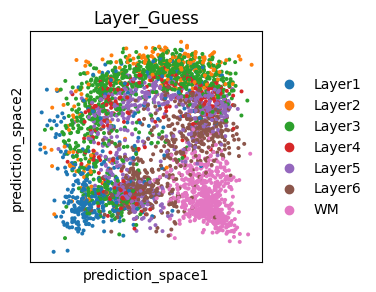

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
test=torch.tensor(sc_adata.X, dtype=torch.float32)
with torch.no_grad():
    test=test.to(device)
    predictions_normalized = model(test)
predictions_normalized=predictions_normalized.to('cpu')
predictions_array = predictions_normalized.numpy()
sc_adata.obsm['prediction_space'] = predictions_array
plt.rcParams["figure.figsize"] = (3, 3)
sc.pl.embedding(sc_adata, basis='prediction_space', color='Layer_Guess')

## 6. Identify SOGs

In [10]:
top_50_gene_indices, top_50_gene_names = SOGlocate.compute_important_genes_and_indices(model, sc_adata, 50, 2)

## 7. Perform in silico knockouts

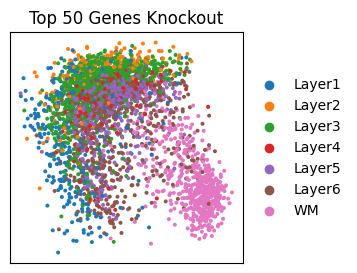

In [11]:
SOGlocate.knockout_and_visualize(model, test, top_50_gene_indices, sc_adata, 'Layer_Guess', 'Top 50 Genes Knockout')

In [12]:
_finish_audit()

[audit] All checked losses, arrays and model parameters are finite.
